In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
TABLES = PROJECT_ROOT / "outputs/tables"
metadata = json.loads((PROJECT_ROOT / "outputs/contamination_metadata.json").read_text())
display(pd.Series(metadata, name="Value").to_frame())

,Value
scope,controlled training-response contamination
training_observations,40000
test_observations,10000
contaminated_training_observations,2000
contamination_fraction,0.05
fare_addition_usd,100.0
seed,42
alpha,0.75
initial_subsets,500
test_set_unchanged,True


,training_scenario,estimator,mae,rmse,median_absolute_error,r_squared
0,clean,OLS,2.086,3.253,1.594,0.923
1,clean,Reweighted LTS,1.015,8.756,0.347,0.445
2,contaminated,OLS,5.383,5.939,5.578,0.745
3,contaminated,Reweighted LTS,1.000,8.737,0.347,0.448


,estimator,clean_mae,contaminated_mae,change_mae,clean_rmse,contaminated_rmse,change_rmse,clean_median_absolute_error,contaminated_median_absolute_error,change_median_absolute_error,clean_r_squared,contaminated_r_squared,change_r_squared
0,OLS,2.086,5.383,3.297,3.253,5.939,2.686,1.594,5.578,3.984,0.923,0.745,-0.179
1,Reweighted LTS,1.015,1.000,-0.015,8.756,8.737,-0.019,0.347,0.347,0.000,0.445,0.448,0.002


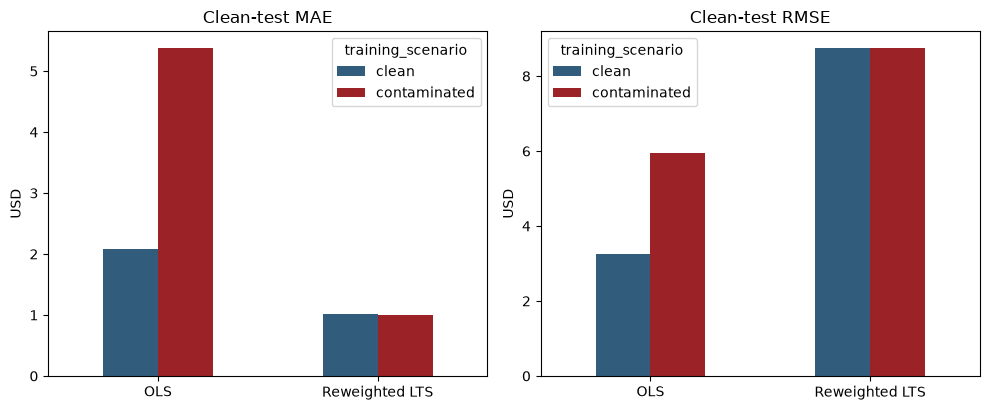

In [2]:
performance = pd.read_csv(TABLES / "contamination_model_performance.csv")
degradation = pd.read_csv(TABLES / "contamination_prediction_degradation.csv")
display(performance.style.format(precision=3))
display(degradation.style.format(precision=3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for axis, metric in zip(axes, ["mae", "rmse"], strict=True):
    pivot = performance.pivot(index="estimator", columns="training_scenario", values=metric)
    pivot.plot.bar(ax=axis, color=["#315C7C", "#9B2226"])
    axis.set(title=f"Clean-test {metric.upper()}", ylabel="USD", xlabel="")
    axis.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

,estimator,term,clean,contaminated,absolute_change,absolute_change_magnitude,percent_change_from_clean
0,OLS,const,5.2406,10.0672,4.8266,4.8266,92.1001
1,OLS,duration_min,0.0824,0.0768,-0.0056,0.0056,-6.7742
2,OLS,is_weekend,-0.7448,-0.7966,-0.0518,0.0518,-6.9484
3,OLS,passenger_count,0.1380,0.1646,0.0266,0.0266,19.2738
4,OLS,pickup_hour_cos,-1.0891,-1.2942,-0.2050,0.2050,-18.8262
5,OLS,pickup_hour_sin,-0.5781,-0.7317,-0.1536,0.1536,-26.5681
6,OLS,trip_distance,3.6218,3.6774,0.0557,0.0557,1.5367
7,Reweighted LTS,const,2.4025,2.3780,-0.0245,0.0245,-1.0209
8,Reweighted LTS,duration_min,0.6050,0.6045,-0.0005,0.0005,-0.0896
9,Reweighted LTS,is_weekend,-0.0115,-0.0123,-0.0008,0.0008,-7.0587


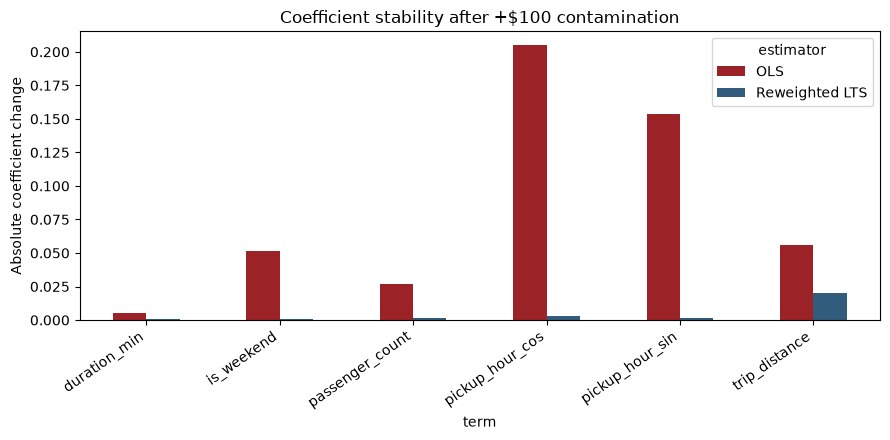

In [3]:
coefficient_change = pd.read_csv(TABLES / "contamination_coefficient_change.csv")
display(coefficient_change.style.format(precision=4))

slopes = coefficient_change.loc[coefficient_change["term"].ne("const")]
pivot = slopes.pivot(index="term", columns="estimator", values="absolute_change_magnitude")
pivot.plot.bar(figsize=(9, 4.5), color=["#9B2226", "#315C7C"])
plt.ylabel("Absolute coefficient change")
plt.title("Coefficient stability after +$100 contamination")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [4]:
detection = pd.read_csv(TABLES / "contamination_detection_summary.csv")
detail = pd.read_csv(TABLES / "contamination_detection_detail.csv")
display(detection.style.format(precision=4))
display(detail.loc[detail["known_artificial_contamination"]].head(15).style.format(precision=3))

,training_observations,known_contaminated,flagged_total,true_positive,false_positive,false_negative,true_negative,detection_recall,detection_precision,false_positive_rate,raw_mad_scale,reweighting_cutoff,audit_residual_cutoff
0,40000,2000,7684,2000,5684,0,32316,1.0000,0.2603,0.1496,0.5533,2.2414,2.5000


,modeling_row_id,source_row_id,pickup_datetime,dropoff_datetime,original_fare_amount,trip_distance,duration_min,passenger_count,pickup_hour_sin,pickup_hour_cos,is_weekend,experimental_fare_amount,known_artificial_contamination,raw_lts_standardized_robust_residual,zero_reweight_flag,absolute_standardized_residual_above_2_5,audit_candidate,detection_class,absolute_standardized_residual
0,41538,37137,2026-01-01 14:01:03,2026-01-01 14:59:09,126.900,33.510,58.100,1.000,-0.500,-0.866,0,226.900,True,232.336,True,True,True,true_positive,232.336
1,10059,1195569,2026-01-15 01:06:40,2026-01-15 01:47:37,98.200,26.810,40.950,1.000,0.259,0.966,0,198.200,True,221.145,True,True,True,true_positive,221.145
2,44090,1802123,2026-01-21 19:15:41,2026-01-21 20:18:51,105.200,25.380,63.167,2.000,-0.966,0.259,0,205.200,True,214.319,True,True,True,true_positive,214.319
3,41574,2118288,2026-01-24 22:04:53,2026-01-24 22:41:34,82.800,22.270,36.683,4.000,-0.500,0.866,1,182.800,True,212.884,True,True,True,true_positive,212.884
4,42731,56917,2026-01-01 19:42:50,2026-01-01 20:16:47,78.600,21.110,33.950,1.000,-0.966,0.259,0,178.600,True,212.178,True,True,True,true_positive,212.178
5,43984,1309807,2026-01-16 07:28:39,2026-01-16 08:28:06,98.200,24.500,59.450,2.000,0.966,-0.259,0,198.200,True,208.373,True,True,True,true_positive,208.373
6,10005,139658,2026-01-02 23:19:35,2026-01-02 23:55:50,74.400,19.250,36.250,4.000,-0.259,0.966,0,174.400,True,208.037,True,True,True,true_positive,208.037
7,46649,540577,2026-01-07 23:51:12,2026-01-08 00:31:23,73.700,18.180,40.183,1.000,-0.259,0.966,0,173.700,True,206.071,True,True,True,true_positive,206.071
8,21753,1418339,2026-01-17 10:30:47,2026-01-17 11:07:11,70.200,17.480,36.400,1.000,0.500,-0.866,1,170.200,True,206.044,True,True,True,true_positive,206.044
9,35098,1572200,2026-01-19 10:22:18,2026-01-19 10:57:41,69.500,17.800,35.383,4.000,0.500,-0.866,0,169.500,True,204.734,True,True,True,true_positive,204.734


/Users/ak007/Projects/Regression_Techniques_Project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Display design
comparable_trips,1038
displayed_unchanged,250
displayed_artificial,48
x_max,40.53225
reference_distance,1.53
distance_window,"[1.18, 1.88]"
training_size,40000
contaminated_training_size,2000
models_refitted_for_plot,False


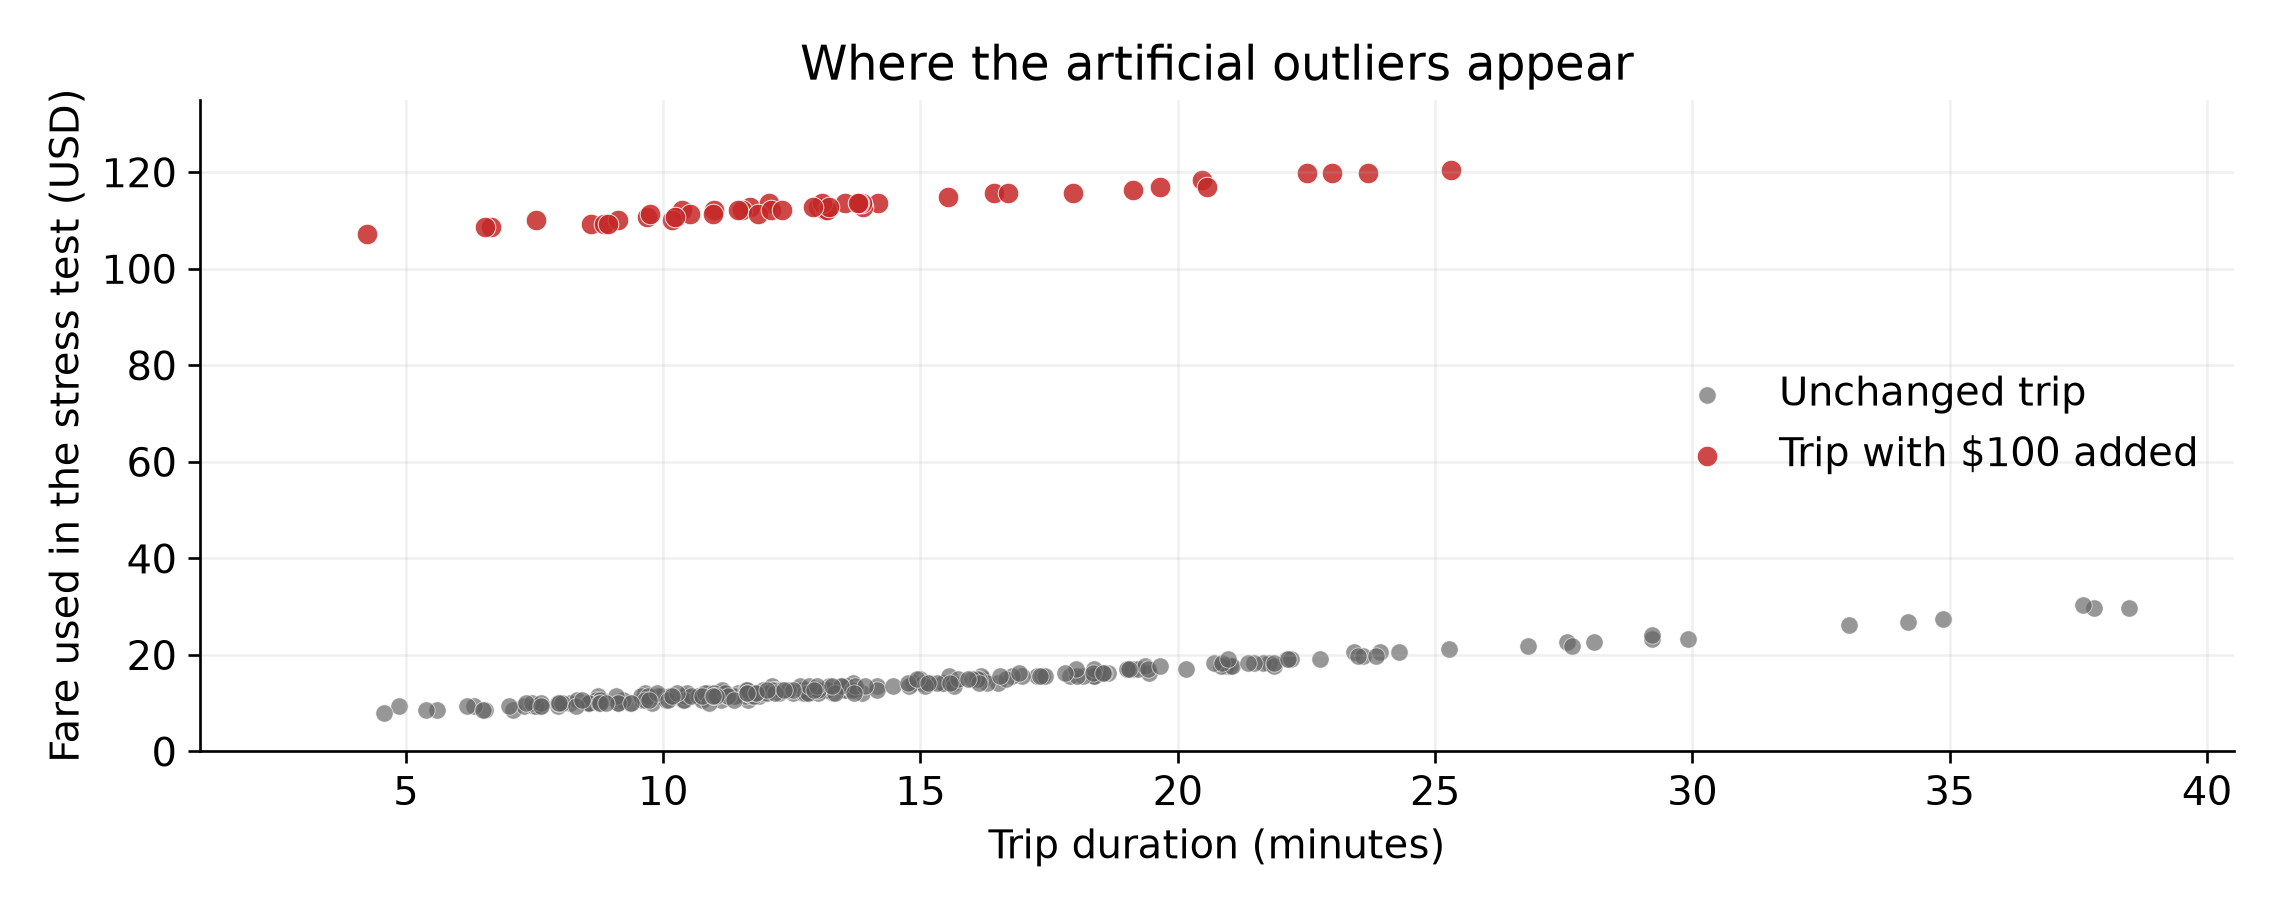

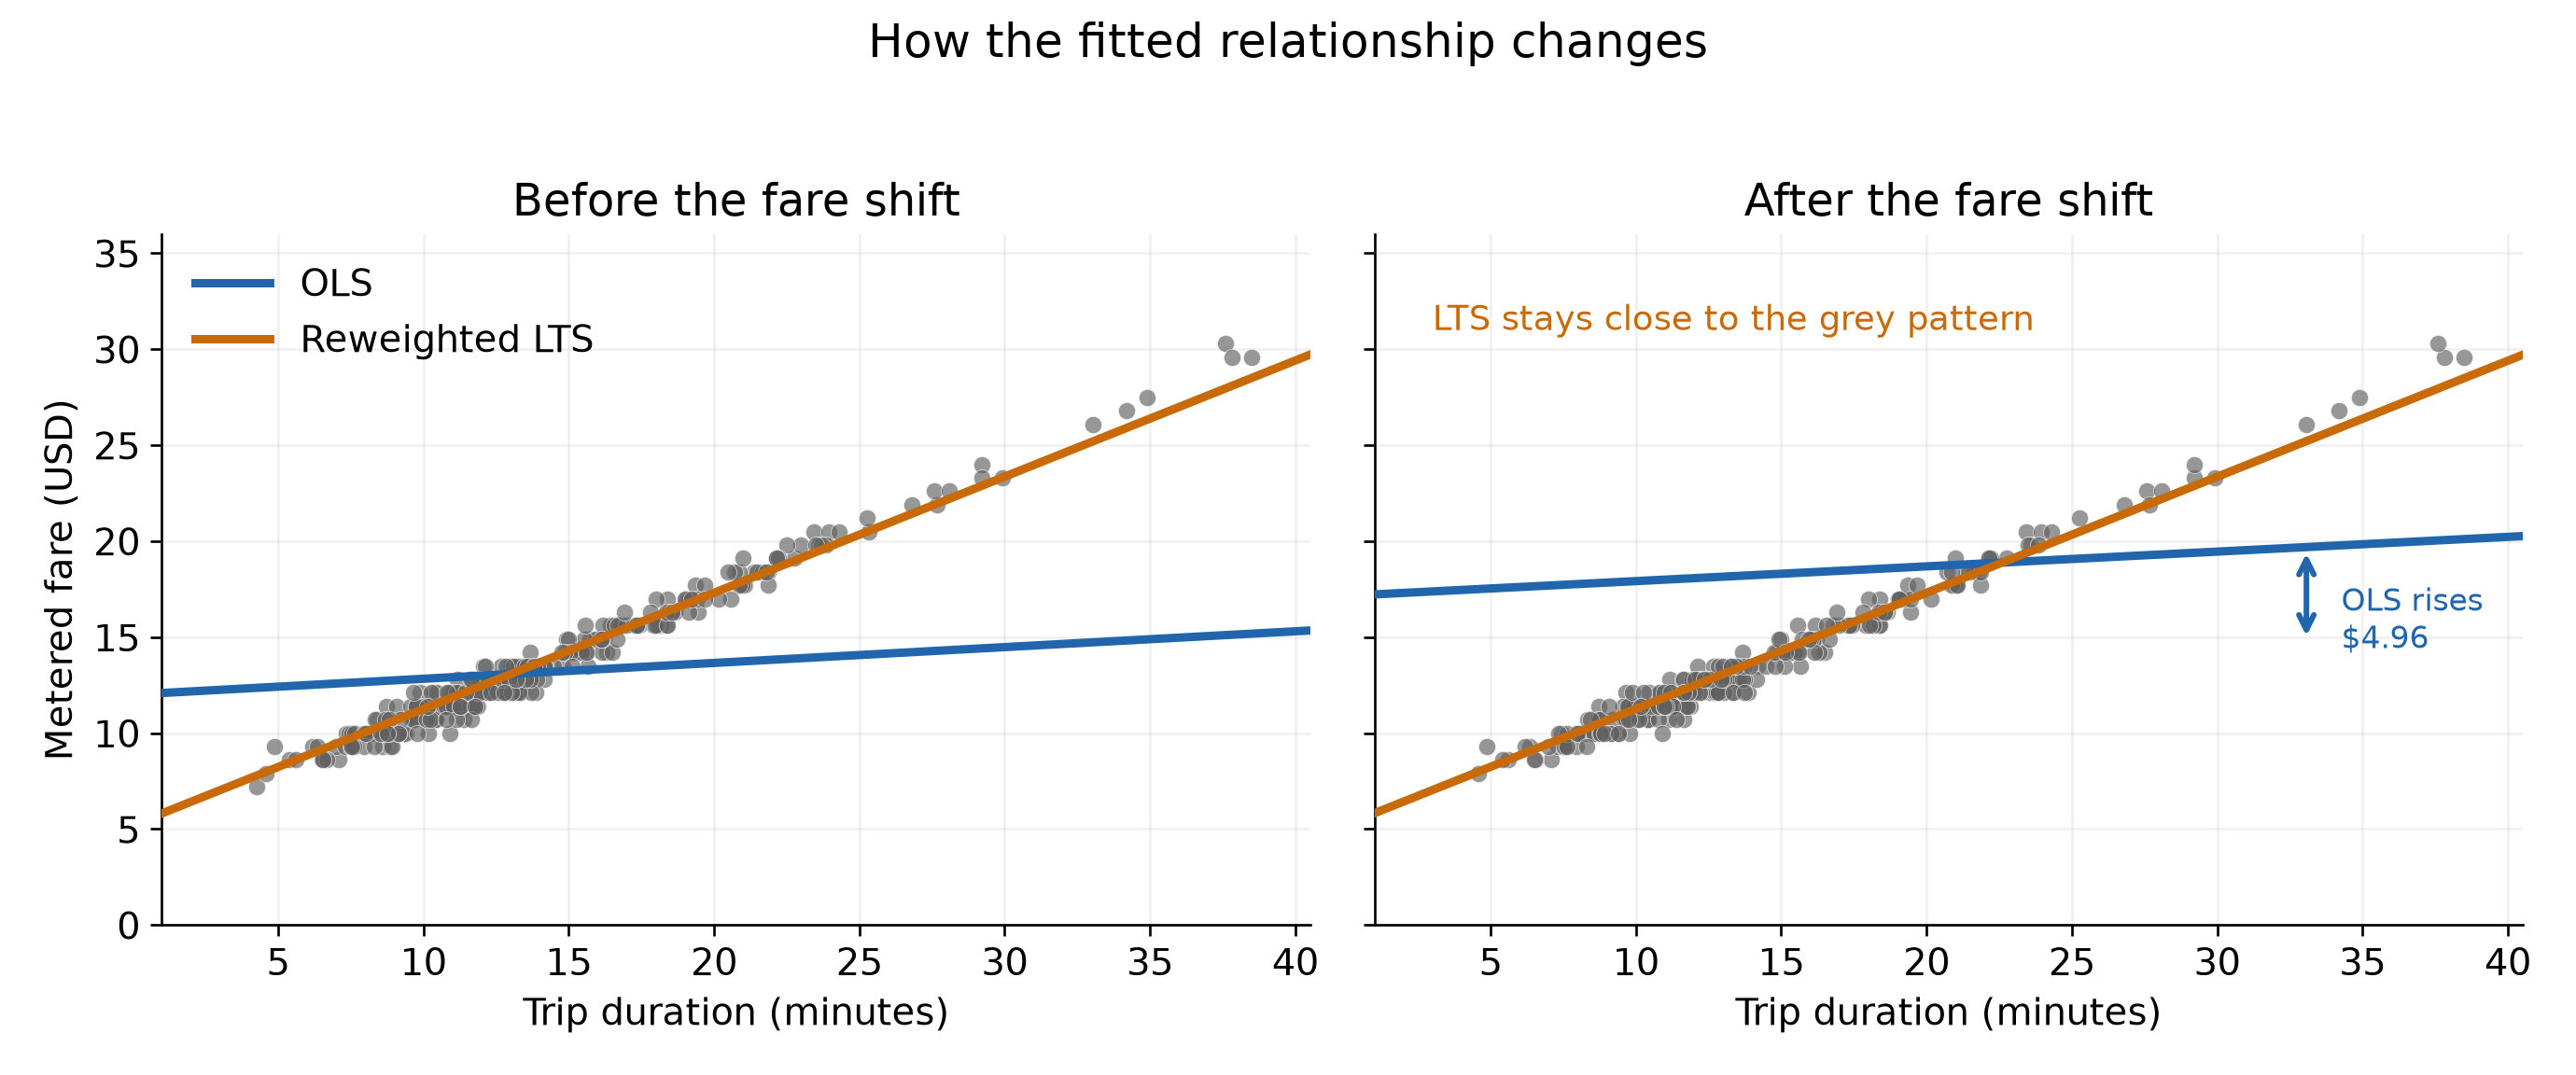

In [5]:
from IPython.display import Image
from src.taxi_lts.plot_actual_points import save_comparable_trip_plots
from src.taxi_lts.stress_test import contaminate_training_response

modeling = pd.read_csv(PROJECT_ROOT / "data/processed/taxi_modeling_50000.csv")
training = modeling.loc[modeling["split"].eq("train")].copy()
_, known_mask = contaminate_training_response(training)
coefficients = pd.read_csv(TABLES / "contamination_coefficient_change.csv")
plot_details = save_comparable_trip_plots(
    training, coefficients, known_mask, PROJECT_ROOT / "outputs/figures"
)
display(pd.Series(plot_details, name="Display design").to_frame())
display(Image(filename=PROJECT_ROOT / "outputs/figures/actual_contamination_overview.png"))
display(Image(filename=PROJECT_ROOT / "outputs/figures/actual_points_clean_stress_fitted_lines.png"))